In [1]:
from typing_extensions import TypedDict


class State(TypedDict):
    graph_info:str

In [ ]:
def start_play(state:State):
    print("Start play node has been called")
    return {"graph_info":state["graph_info"]+ "I am planning to play "}

def cricket(state:State):
    print("Cricket node has been called")
    return {"graph_info":state["graph_info"]+ " cricket"}

def batminton(state:State):
    print("my badminton has been called")
    return {"graph_info":state["graph_info"]+ " batminton"}



In [5]:
import random
from typing import Literal

def random_play(state:State)->Literal['cricket','batminton']:
    if random.random()>0.5:
        return "cricket"
    else:
        return "batminton"

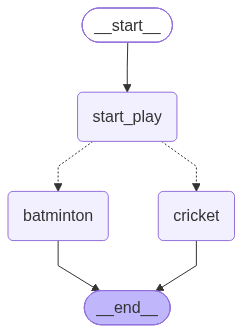

In [19]:
from IPython.display import Image,display

from langgraph.graph import StateGraph,START,END

graph=StateGraph(State)

graph.add_node("start_play",start_play)
graph.add_node("cricket",cricket)
graph.add_node("batminton",batminton)

graph.add_edge(START,"start_play")
graph.add_conditional_edges("start_play",random_play)
graph.add_edge('cricket',END)
graph.add_edge('batminton',END)

build_graph=graph.compile()

display(Image(build_graph.get_graph().draw_mermaid_png()))

In [20]:
build_graph.invoke({'graph_info':'myself sayeed'})

Start play node has been called
Cricket node has been called


{'graph_info': 'myself sayeedI am planning to playcricket'}